# 01 - Exploratory data analysis (run after `python -m src.ingest`)
Reads the bronze layer. Only small aggregates are brought to pandas.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from src.common.config import load_config, data_path, results_dir
from src.common.spark_session import get_spark

cfg = load_config()
spark = get_spark("notebook", cfg)

26/11/19 18:42:12 WARN Utils: Your hostname, DESKTOP-23Q32ON resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 18:42:12 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 18:42:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
bronze = spark.read.parquet(data_path(cfg, "bronze", "reviews"))
bronze.printSchema()
print("rows:", bronze.count())
print("first/last year:", bronze.agg(F.min("year"), F.max("year")).first())   # needed for experiment E5 (temporal cutoff)

root
 |-- rating: double (nullable = true)
 |-- title: string (nullable = true)
 |-- text: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- parent_asin: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- helpful_vote: integer (nullable = true)
 |-- verified_purchase: boolean (nullable = true)
 |-- review_ts: timestamp (nullable = true)
 |-- month: integer (nullable = true)
 |-- review_id: string (nullable = true)
 |-- year: integer (nullable = true)



rows: 997074


[Stage 4:====================================>                      (5 + 3) / 8]

first/last year: Row(min(year)=2000, max(year)=2023)


## Rating distribution

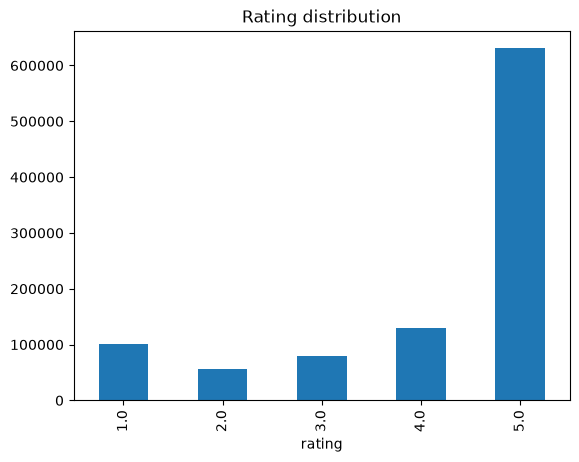

In [3]:
r = bronze.groupBy("rating").count().orderBy("rating").toPandas()
r.plot.bar(x="rating", y="count", legend=False, title="Rating distribution"); plt.show()

## Review length (words)

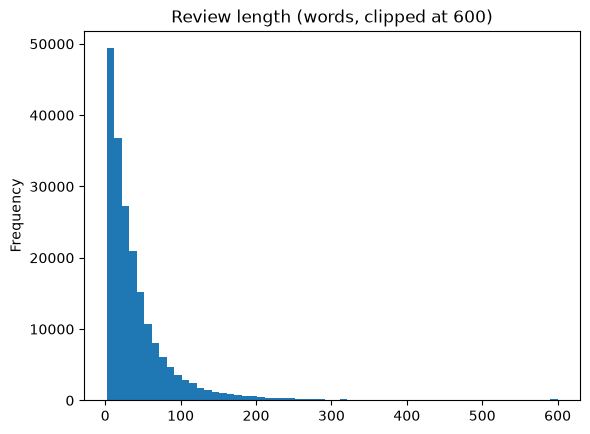

In [4]:
lens = (bronze.sample(False, min(1.0, 200000 / bronze.count()), 42)
              .select(F.size(F.split(F.concat_ws(". ", "title", "text"), r"\s+")).alias("words")).toPandas())
lens["words"].clip(upper=600).plot.hist(bins=60, title="Review length (words, clipped at 600)"); plt.show()

## Reviews per year

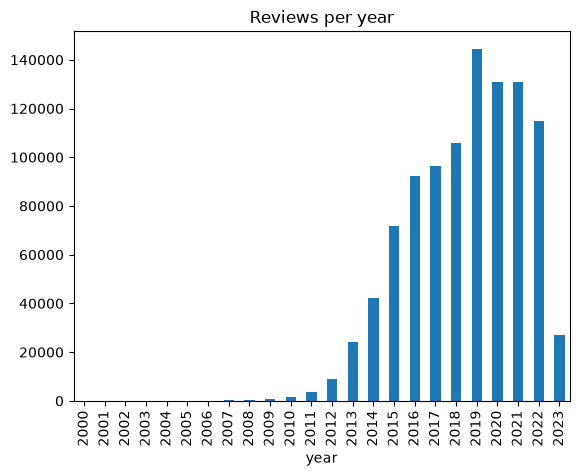

In [5]:
y = bronze.groupBy("year").count().orderBy("year").toPandas()
y.plot.bar(x="year", y="count", legend=False, title="Reviews per year"); plt.show()

## Class balance after labeling (positive vs negative)
Requires silver (`python -m src.clean`). Expect a heavy positive skew.

In [6]:
silver_path = data_path(cfg, "silver", "reviews")
try:
    silver = spark.read.parquet(silver_path)
    lab = silver.groupBy("label").count().toPandas()
    lab["label"] = lab["label"].map({1.0: "positive", 0.0: "negative"})
    print(lab); lab.plot.bar(x="label", y="count", legend=False, title="Class balance (silver)"); plt.show()
except Exception as e:
    print("silver not available yet:", type(e).__name__)

silver not available yet: AnalysisException


## Top 20 products by review count

In [7]:
top = bronze.groupBy("parent_asin").count().orderBy(F.desc("count")).limit(20).toPandas()
meta = spark.read.parquet(data_path(cfg, "bronze", "meta")).select("parent_asin", "title").toPandas()
top.merge(meta, on="parent_asin", how="left")

,parent_asin,count,title
0,B00JRGOKQ8,3996,iOttie Easy One Touch 2 Car Mount Holder Unive...
1,B09TSCZWX5,2920,"pop-tech Car Grips Mount for Phone Stand, 2 Pa..."
2,B07LBCWZ2N,2442,JETech Replacement Band for Apple Watch 42mm a...
3,B01415QHYW,2288,amFilm Screen Protector 4.7“ for Apple iPhone ...
4,B07KJH11VV,1835,Cell Phone Clip On Stand Holder with Grip Flex...
5,B01BZC262Q,1784,iOttie Easy One Touch 3 IPhone XS MAX R 8 Plus...
6,B07K6J2WPN,1763,iPhone 8 Plus / 7 Plus Matte Glass Screen Prot...
7,B07P9S6R9Y,1514,"Yootech Wireless Charger,10W Max Fast Wireless..."
8,B01ITNRGFG,1233,JOTO Universal Waterproof Phone Pouch Cellphon...
9,B07H2V5YLH,1202,Ailun Glass Screen Protector Compatible for iP...


## Verified purchases and missing values

In [8]:
print(bronze.agg(F.avg(F.col("verified_purchase").cast("double")).alias("share_verified")).first())
nulls = bronze.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in bronze.columns]).toPandas().T
nulls.columns = ["nulls"]; nulls

Row(share_verified=0.937636524470601)


,nulls
rating,0
title,0
text,0
asin,0
parent_asin,0
user_id,0
helpful_vote,0
verified_purchase,0
review_ts,0
month,0


## Data-quality assertions

In [9]:
n = bronze.count()
assert bronze.select("review_id").distinct().count() == n, "review_id not unique"
assert bronze.filter(~F.col("rating").between(1.0, 5.0)).count() == 0, "rating outside [1, 5]"
print("bronze checks passed")

bronze checks passed


In [10]:
spark.stop()